In [28]:
 #!/usr/bin/env python
# coding: utf-8

# In[1]:


# JPK qi data to text file in .xyzc format conversion program
# command format: qi2txt input_file output_file
# input_file: name of the input file (including its path if necessary)
# output_file: name of the output file (including its path if necessary)

import zipfile
import io
import numpy as np
import struct
import matplotlib.pyplot as plt
import re
import time
import sys
import pandas as pd
from scipy import interpolate


# 入出力ファイルのパスを取得
QI_FILES = ["qi1.jpk-qi-data", "qi2.jpk-qi-data", "qi3.jpk-qi-data", "qi4.jpk-qi-data", "qi5.jpk-qi-data", "qi6.jpk-qi-data", "qi7.jpk-qi-data", "qi8.jpk-qi-data"]
ANS_FILES = ["qi1.txt", "qi2.txt", "qi3.txt", "qi4.txt", "qi5.txt", "qi6.txt", "qi7.txt", "qi8.txt"]
N_Z_PTS = 256
fcs = []
ans = []
n_pts_max = 0

start_time = time.perf_counter()

for f_num, file in enumerate(QI_FILES):
    print("Reading data from " + file)

    with zipfile.ZipFile(file) as zf:
        # shared-data/header.propertiesからのパラメータの読み込み
        with zf.open("shared-data/header.properties") as f:
            f.readline()
            sh_param = {}
            for b_line in f:
                s_line = b_line.decode("utf-8")
                m = re.search("=",s_line)
                sh_param[s_line[:m.end()-1]]=s_line[m.end():]

        # channelの名前と番号の辞書を作成
        ch = {}
        i = 0
        while True:
            try:
                ch_name=sh_param["lcd-info."+str(i)+".channel.name"][:-1]
                ch[ch_name]= i
                i += 1
            except KeyError:
                break

        # z data（measuredHeight）のスケーリングパラメータの取得
        ch_num = ch["measuredHeight"]
        z_offset1 = float(sh_param["lcd-info."+str(ch_num)+".encoder.scaling.offset"])
        z_multi1 = float(sh_param["lcd-info."+str(ch_num)+".encoder.scaling.multiplier"])
        z_offset2 = float(sh_param["lcd-info."+str(ch_num)+".conversion-set.conversion.nominal.scaling.offset"])
        z_multi2 = float(sh_param["lcd-info."+str(ch_num)+".conversion-set.conversion.nominal.scaling.multiplier"])

        # force data (vDeflection)のスケーリングパラメータの取得
        ch_num = ch["vDeflection"]
        f_offset1 = float(sh_param["lcd-info."+str(ch_num)+".encoder.scaling.offset"])
        f_multi1 = float(sh_param["lcd-info."+str(ch_num)+".encoder.scaling.multiplier"])
        f_offset2 = float(sh_param["lcd-info."+str(ch_num)+".conversion-set.conversion.distance.scaling.offset"])
        f_multi2 = float(sh_param["lcd-info."+str(ch_num)+".conversion-set.conversion.distance.scaling.multiplier"])
        f_offset3 = float(sh_param["lcd-info."+str(ch_num)+".conversion-set.conversion.force.scaling.offset"])
        f_multi3 = float(sh_param["lcd-info."+str(ch_num)+".conversion-set.conversion.force.scaling.multiplier"])

        # root folderのheader.propertiesファイルからイメージングパラメータの読み込み
        with zf.open("header.properties") as f:
            f.readline()
            qi_param = {}
            for b_line in f:
                s_line = b_line.decode("utf-8")
                m = re.search("=",s_line)
                qi_param[s_line[:m.end()-1]]=s_line[m.end():]

        # QI imagingに関するパラメータ変数の設定
        x_pix = int(qi_param["quantitative-imaging-map.position-pattern.grid.ilength"])
        y_pix = int(qi_param["quantitative-imaging-map.position-pattern.grid.jlength"])
        xy_pix = x_pix*y_pix
        
        z_pix = 0
        for i in range(xy_pix):
            with zf.open("index/"+str(i)+"/header.properties") as f:
                for b_line in f:
                    s_line = b_line.decode("utf-8")
                    m = re.search("quantitative-imaging-series.header.quantitative-imaging-settings.extend.num-points=",s_line)
                    if m != None:
                        z_pix = max(z_pix,int(s_line[m.end():]))
        #z_pix = int(sh_param["force-segment-header-info."+str(ch["vDeflection"])+".settings.segment-settings.num-points"])

        # force map dataとその分類エータを格納する変数の作成
        fmap = np.empty((x_pix,y_pix,z_pix,2))

        # xy scannerのイメージング開始位置とイメージの走査範囲を取得
        x_start = float(qi_param["quantitative-imaging-map.environment.xy-scanner-position-map.xy-scanner.tip-scanner.start-position.x"])
        y_start = float(qi_param["quantitative-imaging-map.environment.xy-scanner-position-map.xy-scanner.tip-scanner.start-position.y"])
        x_range = float(qi_param["quantitative-imaging-map.position-pattern.grid.ulength"])
        y_range = float(qi_param["quantitative-imaging-map.position-pattern.grid.vlength"])
        x_step = x_range/x_pix
        y_step = y_range/y_pix

        # ANS_FILESからクラス分類の正解情報を得る
        df = pd.read_csv("qi"+str(f_num+1)+".txt", sep="\t")
        df = df.dropna()
        
        # z (measuredHeight) dataの読み込み
        for j in range(y_pix):
            for i in range(x_pix):
                with zf.open("index/"+str(i+j*x_pix)+"/segments/0/channels/measuredHeight.dat") as f:
                    b = f.read()
                    fh=io.BytesIO(b)
                    n_pts = int(len(b)/4)
                    for k in range(n_pts):
                        byte=fh.read(4)
                        z = float(struct.unpack('>i',byte)[0])
                        z = z_multi1*z + z_offset1
                        z = z_multi2*z + z_offset2
                        fmap[i,j,k,0] = z
                    if n_pts<z_pix:
                        fmap[i,j,n_pts:,0] = None

        # force (vDeflection) dataの読み込み
        for j in range(y_pix):
            for i in range(x_pix):
                with zf.open("index/"+str(i+j*x_pix)+"/segments/0/channels/vDeflection.dat") as f:
                    b = f.read()
                    fh=io.BytesIO(b)
                    n_pts = int(len(b)/4)
                    for k in range(n_pts):
                        byte=fh.read(4)
                        force = float(struct.unpack('>i',byte)[0])
                        force = f_multi1*force + f_offset1
                        force = f_multi2*force + f_offset2
                        force = f_multi3*force + f_offset3
                        fmap[i,j,k,1] = force
                    if n_pts<z_pix:
                        fmap[i,j,n_pts:,1] = None
                    n_pts_max = max(n_pts_max,n_pts)
                    
                # fcsとansへの値の代入
                x = fmap[i,j,:,0]
                y = fmap[i,j,:,1]
                f = interpolate.interp1d(x,y, kind="linear")
                x1 = np.linspace(min(x), max(x), N_Z_PTS)
                y1 = f(x1)
#               y1 -= y1[-1]
                fcs.append(y1)
                ans.append(df.iloc[i*x_pix+j,2])

end_time = time.perf_counter()
time_lapse = end_time - start_time
print (f"Conversion was finished in {time_lapse:.1f} sec.")


Reading data from qi1.jpk-qi-data
Reading data from qi2.jpk-qi-data
Reading data from qi3.jpk-qi-data
Reading data from qi4.jpk-qi-data
Reading data from qi5.jpk-qi-data
Reading data from qi6.jpk-qi-data
Reading data from qi7.jpk-qi-data
Reading data from qi8.jpk-qi-data
Conversion was finished in 20.8 sec.


## Data Preperation

In [52]:
X= fcs
len(X)
X = np.stack(X).astype(np.float32)    # shape becomes (N, 256)
X.shape

(2048, 256)

In [53]:
# X_raw shape = (N, 256)

# Normalize
mean = X.mean(axis=1, keepdims=True)
std = X.std(axis=1, keepdims=True) + 1e-12
X_norm = (X - mean) / std

# Derivative
X_deriv = np.diff(X_norm, axis=1, prepend=X_norm[:, :1])
#Second Derivative
X_second = np.diff(X_deriv, axis=1, prepend=0)

# Stack 2 channels
X_final = np.stack([X_norm, X_deriv, X_second], axis=1)
X_final.shape


(2048, 3, 256)

In [54]:
y= pd.Series(ans)
#y.value_counts(normalize=True) * 100
y = y.values.astype(np.int64)         # shape (N,)
y.shape


(2048,)

## Pytorch Dataloader

In [70]:
import torch
from torch.utils.data import Dataset

class ForceDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


In [71]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X_final, y, test_size=0.2, random_state=42, stratify=y
)


In [72]:
train_dataset = ForceDataset(X_train, y_train)
val_dataset   = ForceDataset(X_val, y_val)


In [73]:
from torch.utils.data import DataLoader

train_loader = DataLoader(train_dataset,
                          batch_size=64,
                          shuffle=True)

val_loader = DataLoader(val_dataset,
                        batch_size=64,
                        shuffle=False)


In [74]:
for xb, yb in train_loader:
    print(xb.shape, yb.shape)
    break

torch.Size([64, 3, 256]) torch.Size([64])


In [75]:
import torch
import numpy as np
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


class_counts = np.bincount(y)   # count samples in each class
total = len(y)
class_weights = total / (len(class_counts) * class_counts)

class_weights = torch.tensor(class_weights, dtype=torch.float32).to(device)
print(class_weights)


tensor([0.6779, 1.1831, 1.4713])


## Resnet Model

In [76]:
import torch
import torch.nn as nn

class ResidualBlock1D(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=11):
        super().__init__()
        padding = kernel_size // 2
        
        self.conv1 = nn.Conv1d(in_channels, out_channels, kernel_size=kernel_size,
                               padding=padding, bias=False)
        self.bn1 = nn.BatchNorm1d(out_channels)
        self.relu = nn.ReLU(inplace=True)

        self.conv2 = nn.Conv1d(out_channels, out_channels, kernel_size=kernel_size,
                               padding=padding, bias=False)
        self.bn2 = nn.BatchNorm1d(out_channels)

        # Shortcut projection if channels mismatch
        self.shortcut = nn.Sequential()
        if in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv1d(in_channels, out_channels, kernel_size=1, bias=False),
                nn.BatchNorm1d(out_channels)
            )

    def forward(self, x):
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out += self.shortcut(x)
        out = self.relu(out)
        return out


In [77]:
class ResNet1D(nn.Module):
    def __init__(self, num_classes=3):
        super().__init__()

        # Initial convolution ("stem")
        self.stem = nn.Sequential(
            nn.Conv1d(3, 64, kernel_size=11, padding=5, bias=False),
            nn.BatchNorm1d(64),
            nn.ReLU(inplace=True)
        )

        # 3 residual blocks (best for your dataset size & length)
        self.block1 = ResidualBlock1D(64, 64, kernel_size=11)
        self.block2 = ResidualBlock1D(64, 128, kernel_size=7)
        self.block3 = ResidualBlock1D(128, 128, kernel_size=5)
        self.block4 = ResidualBlock1D(128, 128, kernel_size=5)


        # Global average pooling
        self.gap = nn.AdaptiveAvgPool1d(1)

        # Final classifier
        self.fc = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)


        x = self.gap(x)       # (B, 128, 1)
        x = x.squeeze(-1)     # (B, 128)
        x = self.fc(x)        # (B, num_classes)
        return x


In [78]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=0.8):
        super().__init__()
        if alpha is not None:
            self.alpha = torch.tensor(alpha, dtype=torch.float32)
        else:
            self.alpha = None
        self.gamma = gamma

    def forward(self, logits, targets):
        ce_loss = F.cross_entropy(logits, targets, reduction='none')
        probs = torch.softmax(logits, dim=1)
        pt = probs[range(len(targets)), targets]
        focal = ce_loss * (1 - pt) ** self.gamma

        if self.alpha is not None:
            if self.alpha.device != logits.device:
                self.alpha = self.alpha.to(logits.device)
            focal = self.alpha[targets] * focal

        return focal.mean()

    
alpha = torch.tensor([1, 1.5, 2.5]).to(device)
criterion = FocalLoss(alpha=alpha, gamma=2)



C:\Users\Fahim\AppData\Local\Temp\ipykernel_21572\2288262294.py:9: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.alpha = torch.tensor(alpha, dtype=torch.float32)


In [79]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = ResNet1D(num_classes=3).to(device)

# Use class weights you computed earlier
class_weights = torch.tensor([0.678, 1.183, 1.471], dtype=torch.float32).to(device)

#criterion = nn.CrossEntropyLoss(weight=class_weights)

#criterion = FocalLoss(alpha=alpha, gamma=0.8)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=5)

## Training and Validating

In [80]:
def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss, correct, total = 0, 0, 0

    for Xb, yb in loader:
        Xb, yb = Xb.to(device), yb.to(device)

        optimizer.zero_grad()
        logits = model(Xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * Xb.size(0)
        _, pred = torch.max(logits, 1)
        correct += (pred == yb).sum().item()
        total += yb.size(0)

    return total_loss / total, correct / total


In [81]:
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0, 0, 0

    with torch.no_grad():
        for Xb, yb in loader:
            Xb, yb = Xb.to(device), yb.to(device)
            logits = model(Xb)
            loss = criterion(logits, yb)

            total_loss += loss.item() * Xb.size(0)
            _, pred = torch.max(logits, 1)
            correct += (pred == yb).sum().item()
            total += yb.size(0)

    return total_loss / total, correct / total


In [82]:
best_val_acc = 0
best_model_path = "best_resnet.pth"

for epoch in range(1, 50):

    train_loss, train_acc = train_one_epoch(
        model, train_loader, optimizer, criterion, device
    )

    val_loss, val_acc = evaluate(
        model, val_loader, criterion, device
    )

    # 🔥 THIS IS WHERE YOU PLUG THE SCHEDULER
    scheduler.step(val_loss)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), best_model_path)
        print(f"🔥 Saved new best model at epoch {epoch} with Val Acc={val_acc:.4f}")

    print(f"Epoch {epoch:02d}: "
          f"Train Loss={train_loss:.4f}, Acc={train_acc:.3f} | "
          f"Val Loss={val_loss:.4f}, Acc={val_acc:.3f}")


🔥 Saved new best model at epoch 1 with Val Acc=0.4854
Epoch 01: Train Loss=0.7010, Acc=0.454 | Val Loss=0.9309, Acc=0.485
🔥 Saved new best model at epoch 2 with Val Acc=0.5341
Epoch 02: Train Loss=0.6149, Acc=0.474 | Val Loss=0.6121, Acc=0.534
🔥 Saved new best model at epoch 3 with Val Acc=0.5512
Epoch 03: Train Loss=0.5879, Acc=0.546 | Val Loss=0.6060, Acc=0.551
Epoch 04: Train Loss=0.5630, Acc=0.567 | Val Loss=0.6130, Acc=0.439
Epoch 05: Train Loss=0.5635, Acc=0.575 | Val Loss=0.6895, Acc=0.407
Epoch 06: Train Loss=0.5442, Acc=0.578 | Val Loss=0.7344, Acc=0.339
🔥 Saved new best model at epoch 7 with Val Acc=0.5707
Epoch 07: Train Loss=0.5458, Acc=0.582 | Val Loss=0.5506, Acc=0.571
🔥 Saved new best model at epoch 8 with Val Acc=0.6293
Epoch 08: Train Loss=0.5413, Acc=0.587 | Val Loss=0.5514, Acc=0.629
Epoch 09: Train Loss=0.5406, Acc=0.567 | Val Loss=0.8218, Acc=0.344
Epoch 10: Train Loss=0.5215, Acc=0.600 | Val Loss=0.5272, Acc=0.578
Epoch 11: Train Loss=0.4980, Acc=0.620 | Val Loss=

              precision    recall  f1-score   support

           0       0.79      0.77      0.78       202
           1       0.51      0.50      0.50       115
           2       0.72      0.80      0.76        93

    accuracy                           0.70       410
   macro avg       0.67      0.69      0.68       410
weighted avg       0.70      0.70      0.70       410

[[155  41   6]
 [ 35  57  23]
 [  5  14  74]]


<Axes: >

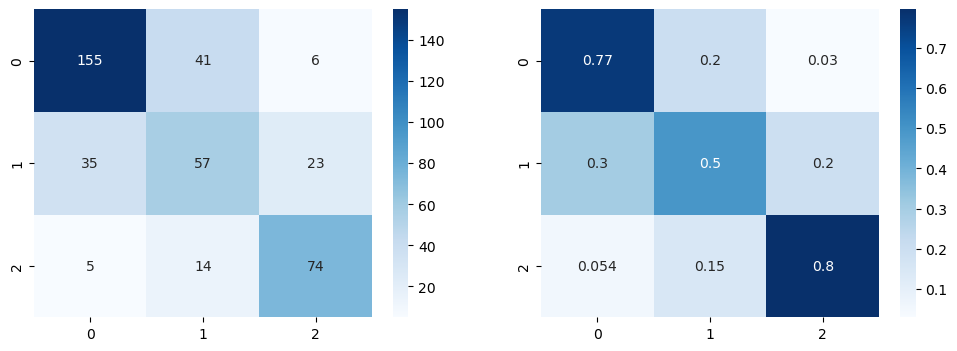

In [83]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for Xb, yb in val_loader:
        Xb, yb = Xb.to(device), yb.to(device)
        logits = model(Xb)
        _, preds = torch.max(logits, 1)
        all_preds.append(preds.cpu())
        all_labels.append(yb.cpu())

all_preds = torch.cat(all_preds).numpy()
all_labels = torch.cat(all_labels).numpy()

print(classification_report(all_labels, all_preds))
print(confusion_matrix(all_labels, all_preds))

cm0 = confusion_matrix(all_labels, all_preds, normalize="true")
cm1 = confusion_matrix(all_labels, all_preds)

fig = plt.figure(figsize=(12,4))
plt.subplot(121)
sns.heatmap(cm1, annot=True, cmap='Blues',fmt='g')
plt.subplot(122)
sns.heatmap(cm0, annot=True, cmap='Blues')


In [51]:
model

ResNet1D(
  (stem): Sequential(
    (0): Conv1d(2, 64, kernel_size=(11,), stride=(1,), padding=(5,), bias=False)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
  )
  (block1): ResidualBlock1D(
    (conv1): Conv1d(64, 64, kernel_size=(11,), stride=(1,), padding=(5,), bias=False)
    (bn1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (conv2): Conv1d(64, 64, kernel_size=(11,), stride=(1,), padding=(5,), bias=False)
    (bn2): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (shortcut): Sequential()
  )
  (block2): ResidualBlock1D(
    (conv1): Conv1d(64, 128, kernel_size=(7,), stride=(1,), padding=(3,), bias=False)
    (bn1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (conv2): Conv1d(128, 128, kernel_size=(7,), stride=(1,), padding=(3,), bias=F

In [ ]:
model.load_state_dict(torch.load("best_resnet1d.pth"))
model.to(device)
model.eval()


C:\Users\Fahim\AppData\Local\Temp\ipykernel_20368\1718682133.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load("best_resnet1d.pth"))


ResNet1D(
  (stem): Sequential(
    (0): Conv1d(2, 64, kernel_size=(11,), stride=(1,), padding=(5,), bias=False)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
  )
  (block1): ResidualBlock1D(
    (conv1): Conv1d(64, 64, kernel_size=(11,), stride=(1,), padding=(5,), bias=False)
    (bn1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (conv2): Conv1d(64, 64, kernel_size=(11,), stride=(1,), padding=(5,), bias=False)
    (bn2): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (shortcut): Sequential()
  )
  (block2): ResidualBlock1D(
    (conv1): Conv1d(64, 128, kernel_size=(7,), stride=(1,), padding=(3,), bias=False)
    (bn1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (conv2): Conv1d(128, 128, kernel_size=(7,), stride=(1,), padding=(3,), bias=F

## Save the model

In [ ]:
torch.save(model, "resnet1d_full_model.pth")


In [ ]:
torch.save(model.state_dict(), "resnet1d_state.pth")



In [ ]:
model = ResNet1D(num_classes=3)
model.load_state_dict(torch.load("resnet1d_state.pth", map_location="cpu"))
model.eval()


C:\Users\Fahim\AppData\Local\Temp\ipykernel_20368\3724842115.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load("resnet1d_state.pth", map_l

ResNet1D(
  (stem): Sequential(
    (0): Conv1d(2, 64, kernel_size=(11,), stride=(1,), padding=(5,), bias=False)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
  )
  (block1): ResidualBlock1D(
    (conv1): Conv1d(64, 64, kernel_size=(11,), stride=(1,), padding=(5,), bias=False)
    (bn1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (conv2): Conv1d(64, 64, kernel_size=(11,), stride=(1,), padding=(5,), bias=False)
    (bn2): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (shortcut): Sequential()
  )
  (block2): ResidualBlock1D(
    (conv1): Conv1d(64, 128, kernel_size=(7,), stride=(1,), padding=(3,), bias=False)
    (bn1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (conv2): Conv1d(128, 128, kernel_size=(7,), stride=(1,), padding=(3,), bias=F

In [ ]:
torch.save(model.state_dict(), "resnet1d_traced.pt")